# Week 6 Day 5 — Comprehensive Mobile Price Analysis

**Daily Challenge | NumPy · Pandas · SciPy · Matplotlib**

**Objective:** Analyze which mobile-phone specifications are associated with the target `price_range` (0–3). The dataset describes phone attributes and price categories, **not actual currency prices**. Conclusions are associations, not causal claims.

**Data source:** [Developers Institute training CSV](https://github.com/devtlv/MiniProject-DataAnalysis-W6D5-Mobile_Price_Classification/blob/main/train.csv). Run the notebook top to bottom; charts and a findings report are generated from the actual data.

## 1. Data Loading and Exploration

In [1]:
# Install if needed: py -m pip install numpy pandas scipy matplotlib seaborn requests jupyter ipykernel
import io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

SEED = 42
np.random.seed(SEED)
OUTPUT = Path('results')
OUTPUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.grid': True, 'grid.alpha': 0.2})
URL = 'https://raw.githubusercontent.com/devtlv/MiniProject-DataAnalysis-W6D5-Mobile_Price_Classification/main/train.csv'

# Prefer a local train.csv (same folder), otherwise retrieve the official CSV.
local = Path('train.csv')
if local.exists():
    df = pd.read_csv(local)
    print('Loaded local:', local.resolve())
else:
    try:
        df = pd.read_csv(URL)
        print('Loaded source:', URL)
    except Exception as exc:
        raise RuntimeError('Download failed. Download train.csv from the provided GitHub repository and place it beside this notebook, then rerun.') from exc

print('Dataset shape:', df.shape)
display(df.head())
print('Column data types:')
display(df.dtypes.to_frame('dtype'))
print('Missing values:')
display(df.isna().sum().to_frame('missing'))
print('Summary statistics:')
display(df.describe(include='all').T)


Loaded source: https://raw.githubusercontent.com/devtlv/MiniProject-DataAnalysis-W6D5-Mobile_Price_Classification/main/train.csv
Dataset shape: (2000, 21)


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1


Column data types:


,dtype
battery_power,int64
blue,int64
clock_speed,float64
dual_sim,int64
fc,int64
four_g,int64
int_memory,int64
m_dep,float64
mobile_wt,int64
n_cores,int64


Missing values:


,missing
battery_power,0
blue,0
clock_speed,0
dual_sim,0
fc,0
four_g,0
int_memory,0
m_dep,0
mobile_wt,0
n_cores,0


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
battery_power,2000.0,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,2000.0,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,2000.0,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,2000.0,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,2000.0,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,2000.0,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,2000.0,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,2000.0,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,2000.0,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,2000.0,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


### Feature descriptions

The dataset commonly includes RAM (`ram`), battery capacity (`battery_power`), internal memory (`int_memory`), screen dimensions (`sc_h`, `sc_w`), clock speed (`clock_speed`), camera resolution (`pc`, `fc`), and binary features such as Bluetooth (`blue`), Wi-Fi (`wifi`), 3G (`three_g`) and 4G (`four_g`). `price_range` is the target with four ordered classes, **0 = lowest and 3 = highest**. Inspect the actual column list above before interpreting individual features.

## 2. Data Cleaning and Preprocessing

In [2]:
target = 'price_range'
if target not in df.columns:
    raise KeyError(f"Required target column {target!r} missing; available columns: {df.columns.tolist()}")
raw_rows = len(df)
df = df.drop_duplicates().copy()
print('Duplicate rows removed:', raw_rows - len(df))

# Convert numerical-looking text to numeric; encode genuine categorical predictors.
for col in df.columns:
    if df[col].dtype == 'object':
        candidate = pd.to_numeric(df[col], errors='coerce')
        if candidate.notna().sum() == df[col].notna().sum():
            df[col] = candidate

if not pd.api.types.is_numeric_dtype(df[target]):
    df[target] = pd.to_numeric(df[target], errors='coerce')
df = df.dropna(subset=[target]).copy()
df[target] = df[target].astype(int)

cat_cols = [c for c in df.columns if c != target and not pd.api.types.is_numeric_dtype(df[c])]
if cat_cols:
    df = pd.get_dummies(df, columns=cat_cols, drop_first=False, dtype=int)
    print('One-hot encoded:', cat_cols)

features = [c for c in df.columns if c != target]
for col in features:
    if df[col].isna().any():
        df[col] = df[col].fillna(df[col].median())

# Flag invalid physical values without guessing how to correct them.
nonnegative_cols = [c for c in features if pd.api.types.is_numeric_dtype(df[c])]
negative_counts = (df[nonnegative_cols] < 0).sum()
print('Negative-value flags (if any):')
print(negative_counts[negative_counts > 0].to_dict())
print('Missing values remaining:', int(df.isna().sum().sum()))
print('Target distribution:')
display(df[target].value_counts().sort_index().rename_axis('price_range').to_frame('count'))
print('Cleaned shape:', df.shape)


Duplicate rows removed: 0
Negative-value flags (if any):
{}
Missing values remaining: 0
Target distribution:


,count
price_range,
0,500
1,500
2,500
3,500


Cleaned shape: (2000, 21)


## 3. Statistical Analysis with NumPy and SciPy

In [3]:
# Comprehensive feature-by-feature descriptive statistics.
rows = []
for col in features:
    x = df[col].dropna().to_numpy(dtype=float)
    if len(x) == 0:
        continue
    modes = stats.mode(x, keepdims=False)
    rows.append({
        'feature': col, 'mean': np.mean(x), 'median': np.median(x),
        'mode': float(modes.mode), 'range': np.ptp(x),
        'variance': np.var(x, ddof=1) if len(x) > 1 else np.nan,
        'std_dev': np.std(x, ddof=1) if len(x) > 1 else np.nan,
        'skewness': stats.skew(x, bias=False) if len(np.unique(x)) > 1 else np.nan,
        'kurtosis_excess': stats.kurtosis(x, bias=False) if len(np.unique(x)) > 1 else np.nan
    })
descriptives = pd.DataFrame(rows).set_index('feature')
display(descriptives.round(3))
descriptives.to_csv(OUTPUT / 'feature_statistics.csv')


,mean,median,mode,range,variance,std_dev,skewness,kurtosis_excess
feature,,,,,,,,
battery_power,1238.518,1226.0,618.0,1497.0,193088.360,439.418,0.032,-1.224
blue,0.495,0.0,0.0,1.0,0.250,0.500,0.020,-2.002
clock_speed,1.522,1.5,0.5,2.5,0.666,0.816,0.178,-1.323
dual_sim,0.509,1.0,1.0,1.0,0.250,0.500,-0.038,-2.001
fc,4.310,3.0,0.0,19.0,18.848,4.341,1.020,0.277
four_g,0.522,1.0,1.0,1.0,0.250,0.500,-0.086,-1.995
int_memory,32.046,32.0,27.0,62.0,329.267,18.146,0.058,-1.216
m_dep,0.502,0.5,0.1,0.9,0.083,0.288,0.089,-1.274
mobile_wt,140.249,141.0,182.0,120.0,1253.136,35.400,0.007,-1.210


In [4]:
# Feature-target associations: Spearman is appropriate for ordered price classes.
correlation_rows = []
for col in features:
    if df[col].nunique() < 2 or df[target].nunique() < 2:
        continue
    rho, pvalue = stats.spearmanr(df[col], df[target], nan_policy='omit')
    correlation_rows.append({'feature': col, 'spearman_rho': rho, 'p_value': pvalue, 'abs_rho': abs(rho)})
correlations = pd.DataFrame(correlation_rows).sort_values('abs_rho', ascending=False)
display(correlations[['feature', 'spearman_rho', 'p_value']].round(5))
correlations.to_csv(OUTPUT / 'feature_target_correlations.csv', index=False)

# Compare all price groups for each nonconstant numeric feature using Kruskal-Wallis.
# Nonparametric: avoids assuming each group is normally distributed.
test_rows = []
for col in features:
    groups = [g[col].dropna().to_numpy(dtype=float) for _, g in df.groupby(target)]
    if len(groups) < 2 or any(len(g) < 2 for g in groups):
        continue
    if len(np.unique(df[col])) < 2:
        continue
    try:
        H, p = stats.kruskal(*groups)
        test_rows.append({'feature': col, 'H_statistic': H, 'p_value': p})
    except ValueError:
        continue
hypothesis_results = pd.DataFrame(test_rows).sort_values('p_value')
# Benjamini-Hochberg FDR correction for testing multiple features.
if len(hypothesis_results):
    m = len(hypothesis_results)
    ranks = np.arange(1, m + 1)
    q = np.minimum.accumulate((hypothesis_results['p_value'].to_numpy() * m / ranks)[::-1])[::-1]
    hypothesis_results['fdr_q_value'] = np.clip(q, 0, 1)
    hypothesis_results['significant_at_0_05'] = hypothesis_results['fdr_q_value'] < 0.05
print('H0: Feature distributions are the same across price ranges.')
print('H1: At least one price group differs. Significance level = 0.05 (FDR adjusted).')
display(hypothesis_results.round(6))
hypothesis_results.to_csv(OUTPUT / 'hypothesis_tests.csv', index=False)


,feature,spearman_rho,p_value
13,ram,0.91708,0.00000
0,battery_power,0.19999,0.00000
12,px_width,0.16513,0.00000
11,px_height,0.13188,0.00000
6,int_memory,0.04428,0.04772
10,pc,0.03282,0.14227
18,touch_screen,-0.03041,0.17399
8,mobile_wt,-0.03021,0.17680
15,sc_w,0.02478,0.26808
4,fc,0.02417,0.28003


H0: Feature distributions are the same across price ranges.
H1: At least one price group differs. Significance level = 0.05 (FDR adjusted).


,feature,H_statistic,p_value,fdr_q_value,significant_at_0_05
13,ram,1681.496474,0.000000,0.000000,True
0,battery_power,90.135750,0.000000,0.000000,True
12,px_width,65.230765,0.000000,0.000000,True
11,px_height,47.181408,0.000000,0.000000,True
8,mobile_wt,10.819251,0.012745,0.050978,False
6,int_memory,8.768458,0.032533,0.108444,False
9,n_cores,7.878417,0.048592,0.138836,False
14,sc_h,6.688037,0.082535,0.206336,False
16,talk_time,4.895142,0.179638,0.399196,False
7,m_dep,4.573047,0.205866,0.411733,False


**Interpretation:** Spearman's rho measures monotonic association with an ordered target; it is not a causal effect. Kruskal–Wallis tests whether groups differ, but a significant result does not identify which pair of groups differs. False discovery rate (FDR) correction reduces the risk of false positives when testing many features.

## 4. Data Visualization with Matplotlib

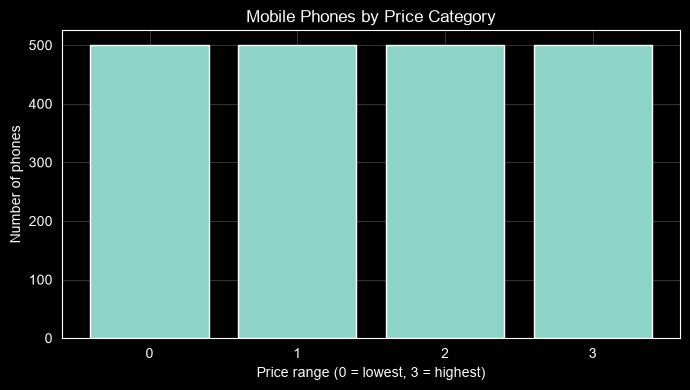

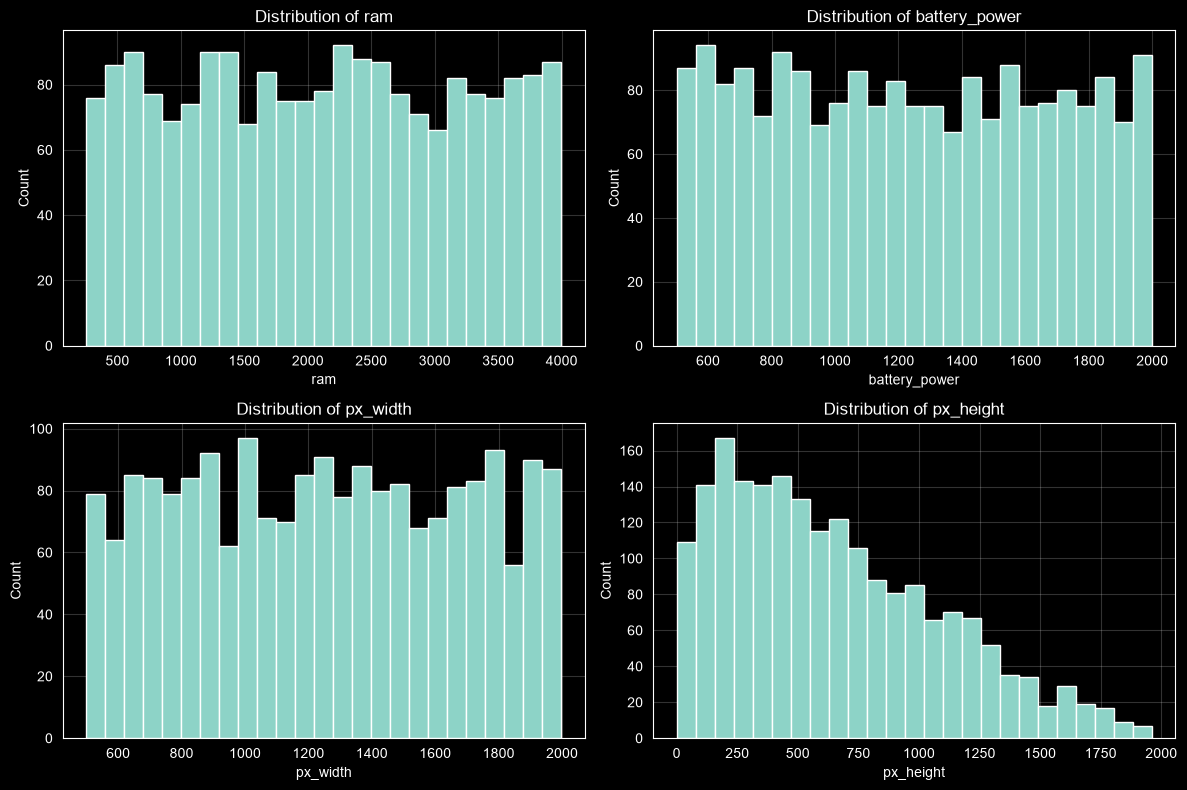

In [5]:
# 1. Target class balance
fig, ax = plt.subplots(figsize=(7, 4))
counts = df[target].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values)
ax.set(title='Mobile Phones by Price Category', xlabel='Price range (0 = lowest, 3 = highest)', ylabel='Number of phones')
fig.tight_layout(); fig.savefig(OUTPUT / '01_price_range_counts.png', dpi=160); plt.show()

# 2. Histograms for the most associated features
plot_features = correlations['feature'].head(4).tolist()
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, plot_features):
    ax.hist(df[col].dropna(), bins=25, edgecolor='white')
    ax.set(title=f'Distribution of {col}', xlabel=col, ylabel='Count')
for ax in axes.flat[len(plot_features):]: ax.axis('off')
fig.tight_layout(); fig.savefig(OUTPUT / '02_feature_histograms.png', dpi=160); plt.show()


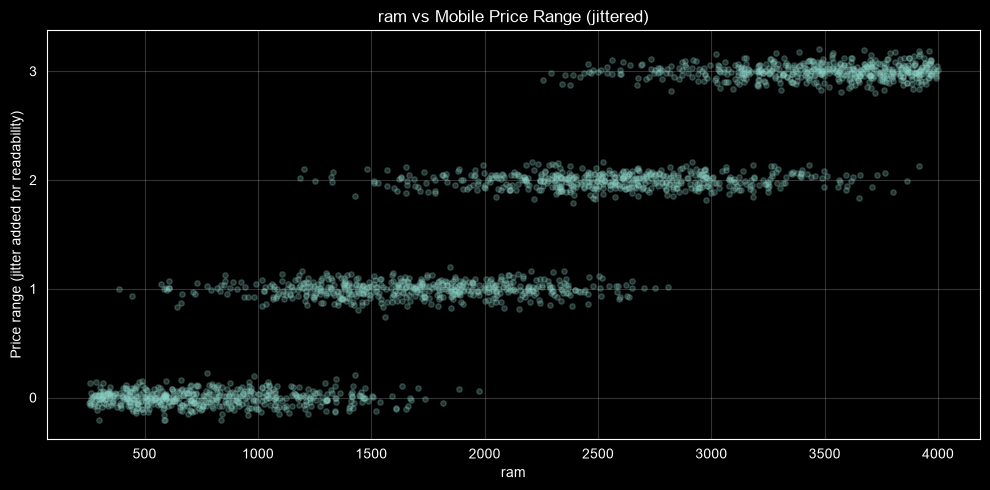

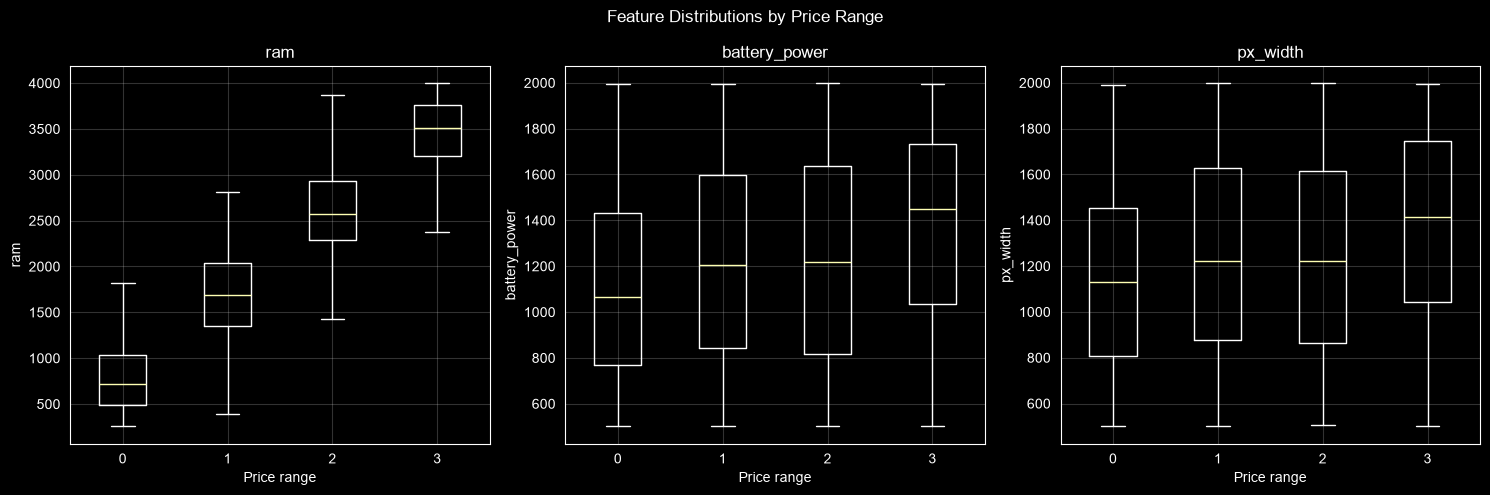

In [6]:
# 3. Scatter plot: strongest-ranked feature vs target with jitter to show overlapping classes
best = correlations.iloc[0]['feature']
rng = np.random.default_rng(42)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df[best], df[target] + rng.normal(0, 0.07, len(df)), alpha=0.25, s=15)
ax.set(title=f'{best} vs Mobile Price Range (jittered)', xlabel=best, ylabel='Price range (jitter added for readability)', yticks=sorted(df[target].unique()))
fig.tight_layout(); fig.savefig(OUTPUT / '03_scatter.png', dpi=160); plt.show()

# 4. Box plots of leading features by price group
box_features = correlations['feature'].head(3).tolist()
fig, axes = plt.subplots(1, len(box_features), figsize=(5 * len(box_features), 5))
axes = np.atleast_1d(axes)
classes = sorted(df[target].unique())
for ax, col in zip(axes, box_features):
    series = [df.loc[df[target] == k, col].dropna() for k in classes]
    ax.boxplot(series, tick_labels=[str(k) for k in classes], showfliers=False)
    ax.set(title=col, xlabel='Price range', ylabel=col)
fig.suptitle('Feature Distributions by Price Range')
fig.tight_layout(); fig.savefig(OUTPUT / '04_boxplots.png', dpi=160); plt.show()


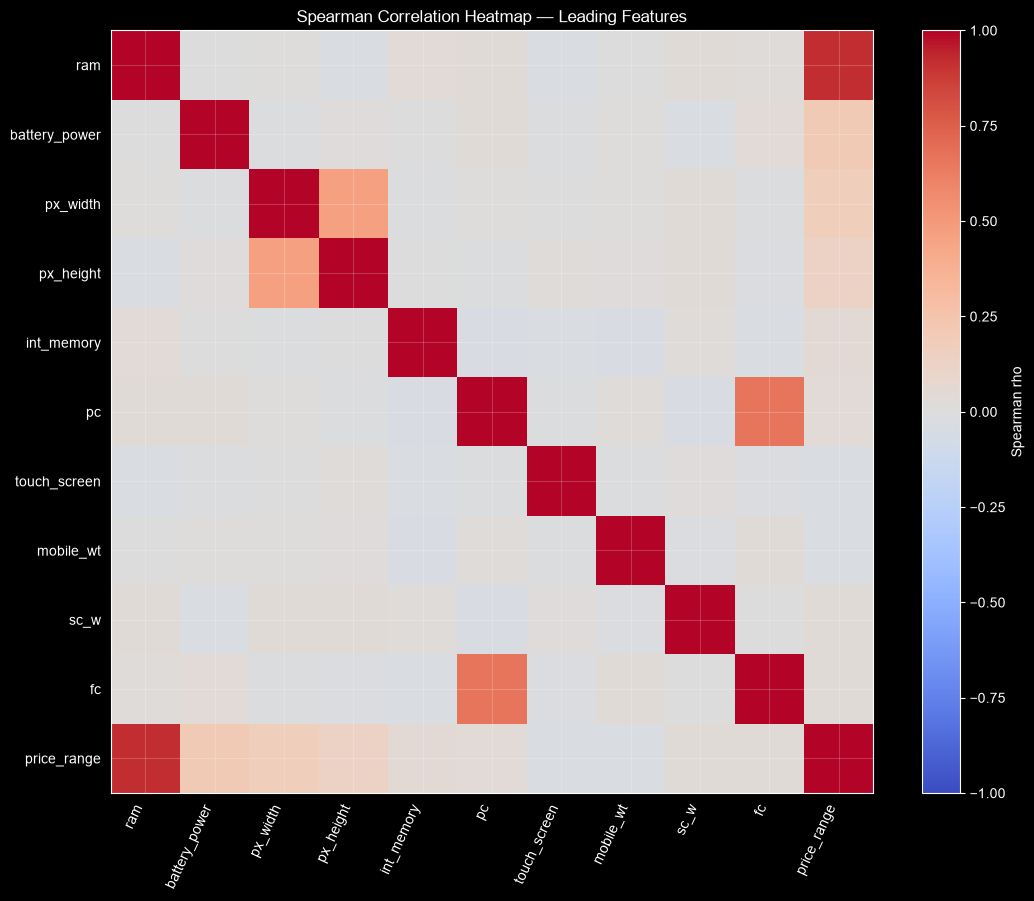

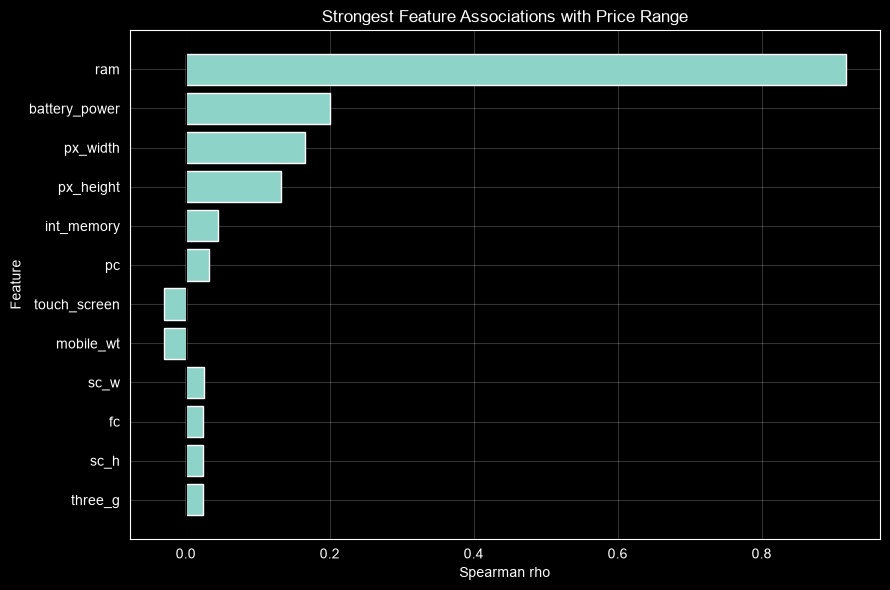

In [7]:
# 5. Correlation heatmap with Matplotlib (no seaborn dependency)
leading = correlations['feature'].head(10).tolist() + [target]
corr_matrix = df[leading].corr(method='spearman')
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(leading)), leading, rotation=65, ha='right')
ax.set_yticks(range(len(leading)), leading)
ax.set_title('Spearman Correlation Heatmap — Leading Features')
fig.colorbar(im, ax=ax, label='Spearman rho')
fig.tight_layout(); fig.savefig(OUTPUT / '05_correlation_heatmap.png', dpi=160); plt.show()

# 6. Rank associations with the target
ranked = correlations.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(ranked['feature'], ranked['spearman_rho'])
ax.axvline(0, color='black', lw=0.8)
ax.set(title='Strongest Feature Associations with Price Range', xlabel='Spearman rho', ylabel='Feature')
fig.tight_layout(); fig.savefig(OUTPUT / '06_feature_correlations.png', dpi=160); plt.show()


## 5. Insight Synthesis and Conclusion

In [8]:
# Report content is computed from the actual dataset, not invented in advance.
leading_features = correlations.head(5)
significant = hypothesis_results.loc[hypothesis_results['significant_at_0_05']] if len(hypothesis_results) else pd.DataFrame()
class_means = df.groupby(target)[leading_features['feature'].tolist()].mean().round(2)

lines = [
    '# Mobile Price Analysis — Findings',
    f'- **Dataset:** {len(df):,} records, {len(features)} predictor columns and {df[target].nunique()} price categories.',
    f'- **Missing values after cleaning:** {int(df.isna().sum().sum())}.',
    f'- **Strongest ranked association:** `{leading_features.iloc[0]["feature"]}` (Spearman rho = {leading_features.iloc[0]["spearman_rho"]:.3f}, p = {leading_features.iloc[0]["p_value"]:.3g}).',
    '- **Five leading features:** ' + ', '.join(f'`{r.feature}` (rho {r.spearman_rho:.3f})' for r in leading_features.itertuples()),
    f'- **Hypothesis tests:** {len(significant)} of {len(hypothesis_results)} features show a difference across price groups after FDR correction (q < 0.05).',
    '- **Caution:** This is an observational classification dataset. Correlation and significant tests do not establish causation; the price categories are ordinal, not monetary values.',
    '- **Actionable next step:** Prioritize strongly associated features for predictive modeling, then validate their usefulness with held-out data and consider multicollinearity.'
]
report = chr(10).join(lines)
display(Markdown(report))
print('Mean leading-feature values by price group:')
display(class_means)
(OUTPUT / 'analysis_report.md').write_text(report + chr(10)*2 + '## Leading feature means by price category' + chr(10)*2 + class_means.to_string(), encoding='utf-8')
print('Saved report and chart files in:', OUTPUT.resolve())


# Mobile Price Analysis — Findings
- **Dataset:** 2,000 records, 20 predictor columns and 4 price categories.
- **Missing values after cleaning:** 0.
- **Strongest ranked association:** `ram` (Spearman rho = 0.917, p = 0).
- **Five leading features:** `ram` (rho 0.917), `battery_power` (rho 0.200), `px_width` (rho 0.165), `px_height` (rho 0.132), `int_memory` (rho 0.044)
- **Hypothesis tests:** 4 of 20 features show a difference across price groups after FDR correction (q < 0.05).
- **Caution:** This is an observational classification dataset. Correlation and significant tests do not establish causation; the price categories are ordinal, not monetary values.
- **Actionable next step:** Prioritize strongly associated features for predictive modeling, then validate their usefulness with held-out data and consider multicollinearity.

Mean leading-feature values by price group:


,ram,battery_power,px_width,px_height,int_memory
price_range,,,,,
0,785.31,1116.90,1150.27,536.41,31.17
1,1679.49,1228.87,1251.91,666.89,32.12
2,2582.82,1228.32,1234.05,632.28,30.92
3,3449.23,1379.98,1369.84,744.85,33.98


Saved report and chart files in: C:\Users\Avi\Desktop\Data\DI_Bootcamp\Week6\Day5\DailyChallenge\results


### Reflection

**Challenges:** Numeric columns may have missing values or inconsistent data types; some binary variables are not normally distributed; price ranges are ordered categories rather than precise prices; multiple feature-level tests inflate false-positive risk.

**Solutions:** Inspect types and null counts, convert numeric-like columns, use median imputation for missing predictors, calculate descriptive statistics with NumPy/SciPy, use Spearman correlation for ordinal associations, use Kruskal–Wallis for group comparisons, and adjust p-values with Benjamini–Hochberg FDR.

**Limitations and future work:** These tests show association, not causal determinants. Test generalization with train/test splits and classification models, check redundant correlated features, and avoid assuming results transfer to today's smartphone market.

**Submission:** Run all cells and save the notebook with outputs before pushing to GitHub. The `results/` folder contains charts, statistics, hypothesis tests, and a generated report.